In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 10

In [2]:
df = pd.read_csv("cleaned_sentiment_data.csv")

In [3]:
df["Platform"] = df["Platform"].astype(str).str.strip()
df["Sentiment_Label"] = df["Sentiment_Label"].astype(str).str.strip()
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

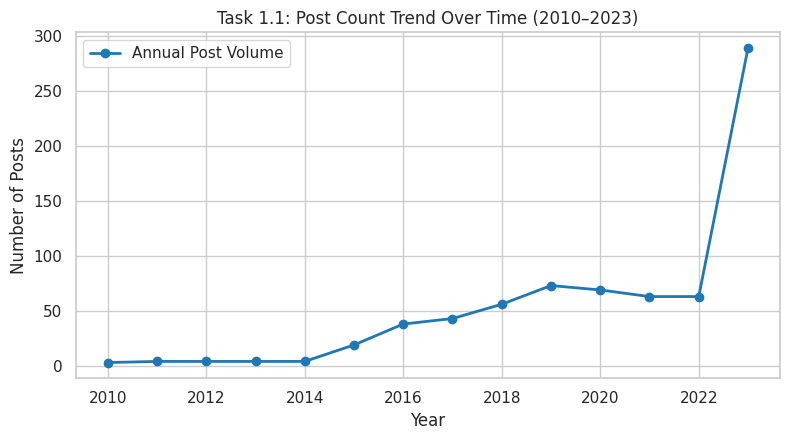

In [4]:
# TASK 1 — Basic Charts (Matplotlib)
# Chart 1: Line Chart
posts_per_year = df["Year"].value_counts().sort_index()

plt.figure(figsize=(8, 4.5))
plt.plot(
    posts_per_year.index,
    posts_per_year.values,
    marker="o",
    color="#1f77b4",
    linewidth=2,
    label="Annual Post Volume",
)
plt.title("Task 1.1: Post Count Trend Over Time (2010–2023)")
plt.xlabel("Year")
plt.ylabel("Number of Posts")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

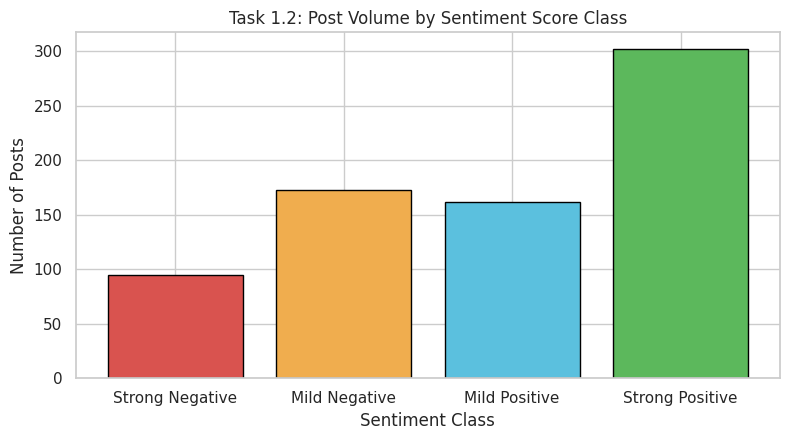

In [5]:
# Chart 2: Bar chart
score_bins = [-1.0, -0.5, 0.0, 0.5, 1.0]
score_labels = [
    "Strong Negative",
    "Mild Negative",
    "Mild Positive",
    "Strong Positive",
]
df["Score_Class"] = pd.cut(
    df["Sentiment_Score"],
    bins=score_bins,
    labels=score_labels,
    include_lowest=True,
)
class_counts = df["Score_Class"].value_counts().loc[score_labels]

plt.figure(figsize=(8, 4.5))
plt.bar(
    class_counts.index,
    class_counts.values,
    color=["#d9534f", "#f0ad4e", "#5bc0de", "#5cb85c"],
    edgecolor="black",
)
plt.title("Task 1.2: Post Volume by Sentiment Score Class")
plt.xlabel("Sentiment Class")
plt.ylabel("Number of Posts")
plt.tight_layout()
plt.show()

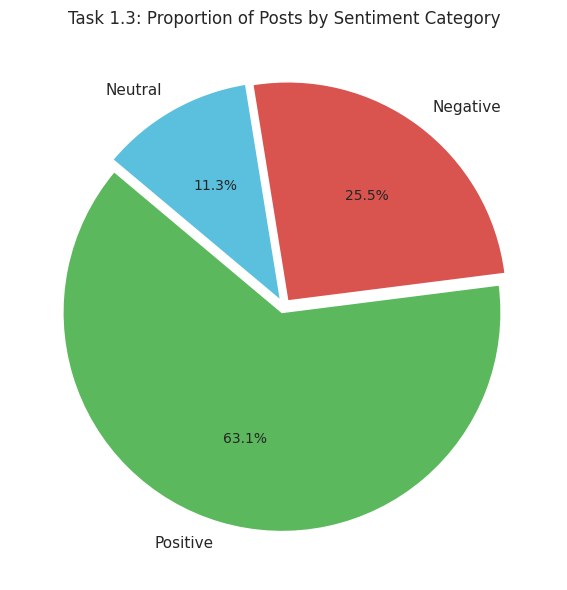

In [6]:
# Chart 3: Pie Chart
sentiment_counts = df["Sentiment_Label"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#5cb85c", "#d9534f", "#5bc0de"],
    explode=[0.03] * len(sentiment_counts),
)
plt.title("Task 1.3: Proportion of Posts by Sentiment Category")
plt.tight_layout()
plt.show()

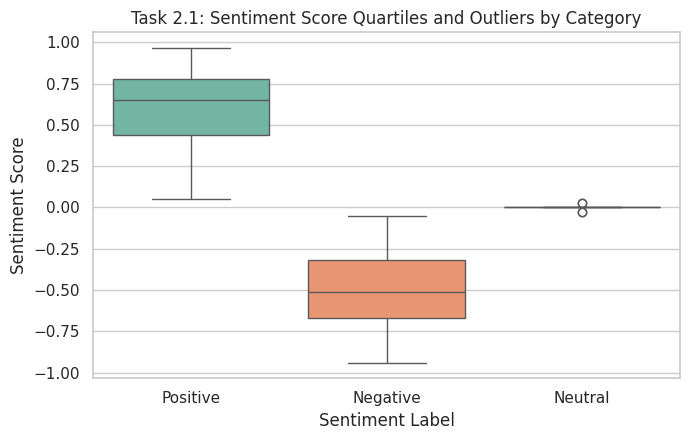

In [7]:
# TASK 2 — Statistical Visualization (Seaborn)
# Chart 4: Box Plot

plt.figure(figsize=(7, 4.5))
sns.boxplot(
    data=df,
    x="Sentiment_Label",
    y="Sentiment_Score",
    palette="Set2",
    hue="Sentiment_Label",
    legend=False,
)
plt.title("Task 2.1: Sentiment Score Quartiles and Outliers by Category")
plt.xlabel("Sentiment Label")
plt.ylabel("Sentiment Score")
plt.tight_layout()
plt.show()

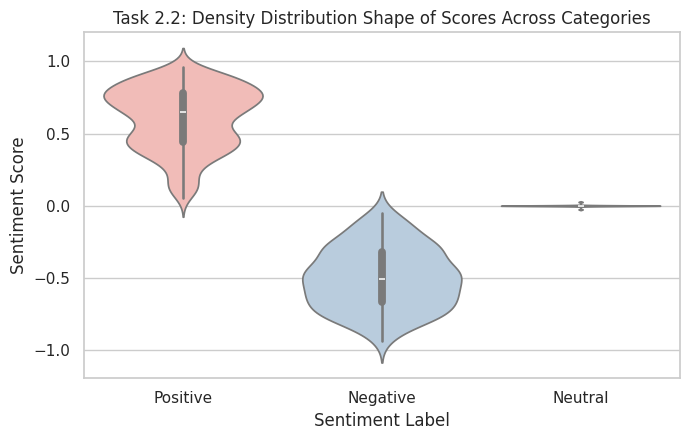

In [8]:
# Chart 5: Violin Plot
plt.figure(figsize=(7, 4.5))
sns.violinplot(
    data=df,
    x="Sentiment_Label",
    y="Sentiment_Score",
    palette="Pastel1",
    hue="Sentiment_Label",
    legend=False,
)
plt.title("Task 2.2: Density Distribution Shape of Scores Across Categories")
plt.xlabel("Sentiment Label")
plt.ylabel("Sentiment Score")
plt.tight_layout()
plt.show()

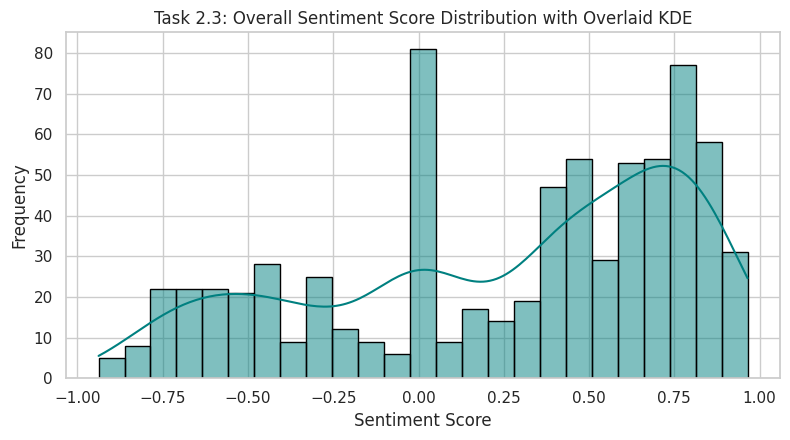

In [9]:
# Chart 6: Histplot with KDE
plt.figure(figsize=(8, 4.5))
sns.histplot(
    data=df,
    x="Sentiment_Score",
    kde=True,
    bins=25,
    color="teal",
    edgecolor="black",
)
plt.title("Task 2.3: Overall Sentiment Score Distribution with Overlaid KDE")
plt.xlabel("Sentiment Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

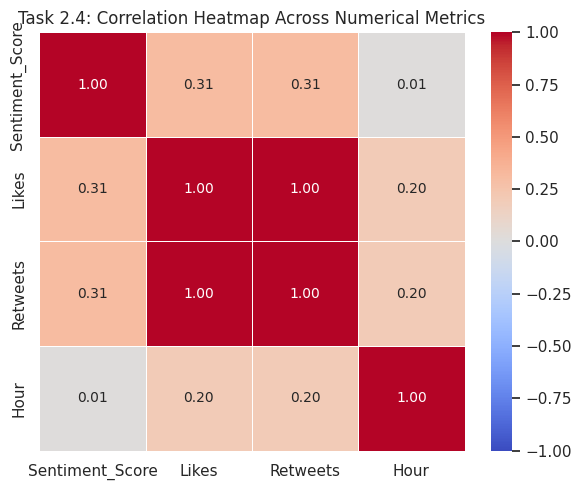

In [10]:
# Chart 7: Heatmap
plt.figure(figsize=(6, 5))
corr_matrix = df[["Sentiment_Score", "Likes", "Retweets", "Hour"]].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)
plt.title("Task 2.4: Correlation Heatmap Across Numerical Metrics")
plt.tight_layout()
plt.show()

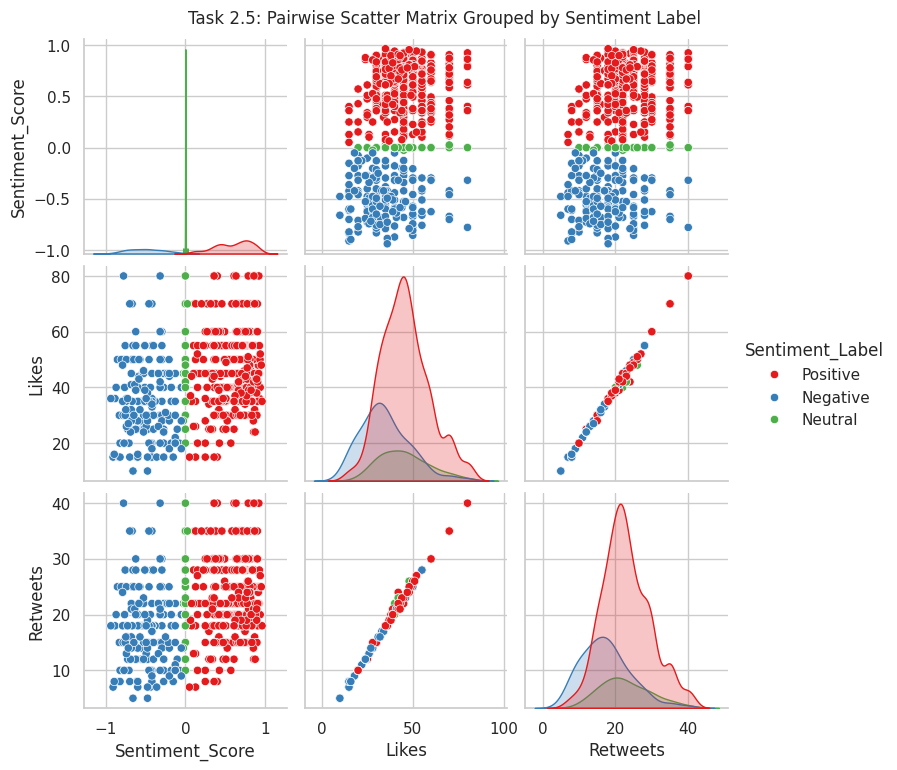

In [11]:
# Chart 8: Pairplot
pairplot_fig = sns.pairplot(
    df[["Sentiment_Score", "Likes", "Retweets", "Sentiment_Label"]],
    hue="Sentiment_Label",
    palette="Set1",
    diag_kind="kde",
)
pairplot_fig.fig.suptitle(
    "Task 2.5: Pairwise Scatter Matrix Grouped by Sentiment Label", y=1.02
)
plt.show()